In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

# EDA  : 

# load dataset : 

dataset = pd.read_csv("../data/raw/dataset-6ab989b678d90892980305.csv")




In [39]:
# look at the agg functions  : 
dataset.describe()

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000
mean,1564.474828,1003.204834,592.437371,411.067645,978.871112,4494.449450,1733.143852
std,2081.531879,2136.634782,1659.887917,904.338115,2097.163877,3638.815725,2895.063757
min,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000
25%,128.281915,39.635000,0.000000,0.000000,0.000000,1600.000000,383.276166
50%,873.385231,361.280000,38.000000,89.000000,0.000000,3000.000000,856.901546
75%,2054.140036,1110.130000,577.405000,468.637500,1113.821139,6500.000000,1901.134317
max,19043.138560,49039.570000,40761.250000,22500.000000,47137.211760,30000.000000,50721.483360


In [40]:
# define dtypes : 
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CUST_ID                 8950 non-null   str    
 1   BALANCE                 8950 non-null   float64
 2   PURCHASES               8950 non-null   float64
 3   ONEOFF_PURCHASES        8950 non-null   float64
 4   INSTALLMENTS_PURCHASES  8950 non-null   float64
 5   CASH_ADVANCE            8950 non-null   float64
 6   CREDIT_LIMIT            8949 non-null   float64
 7   PAYMENTS                8950 non-null   float64
dtypes: float64(7), str(1)
memory usage: 559.5 KB


In [41]:
# check duplicates : 

dataset.loc[dataset.duplicated()]

,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS


In [163]:
# missing values : 


dataset.loc[dataset["CREDIT_LIMIT"].isna()]

,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
5203,C15349,18.400472,0.0,0.0,0.0,186.853063,NaN,9.040017


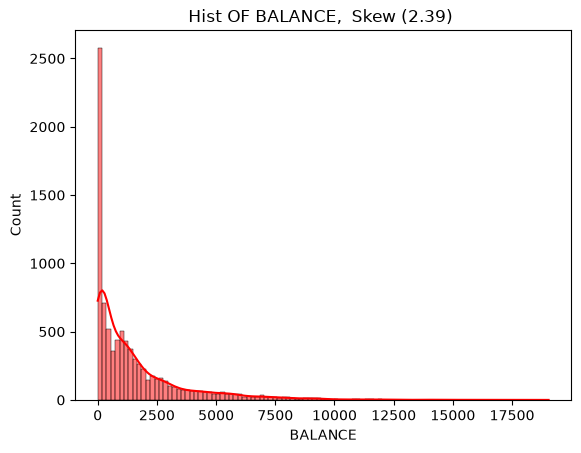

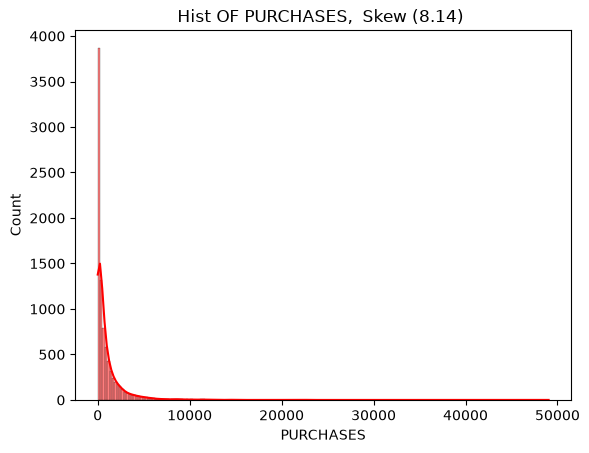

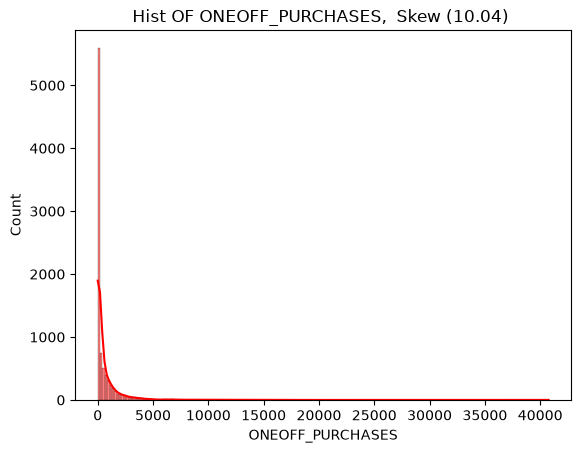

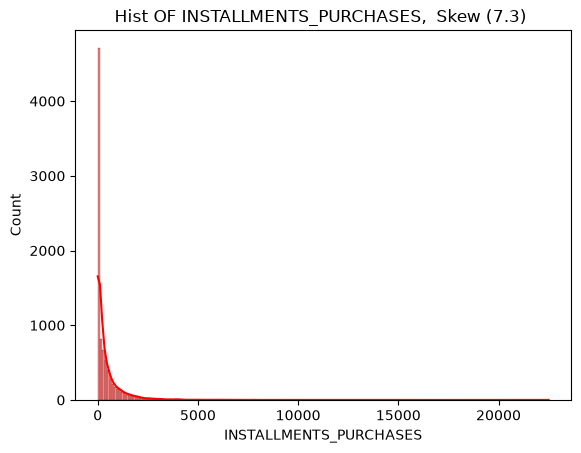

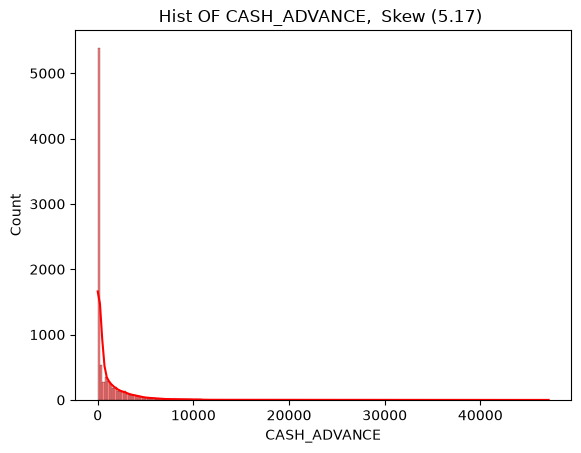

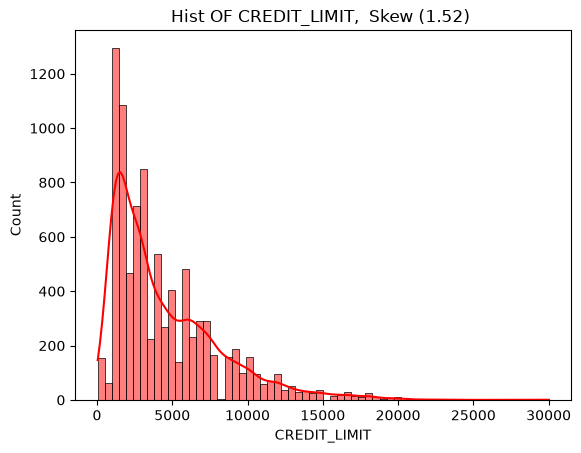

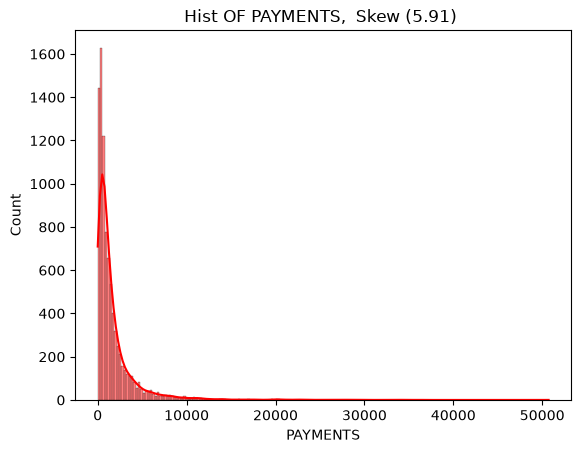

In [139]:
# Visualization : 

list_columns = dataset.columns.to_numpy()
list_columns = np.delete(list_columns , 0)

for column in list_columns : 
    
    sns.histplot(dataset[column] , kde=True , color="red" )

    plt.title(f"Hist OF {column},  Skew ({dataset[column].skew().round(2)}) ")

    plt.show()



In [44]:
# identify skewed variables : 

dataset.select_dtypes(include='number').skew()

BALANCE                    2.393386
PURCHASES                  8.144269
ONEOFF_PURCHASES          10.045083
INSTALLMENTS_PURCHASES     7.299120
CASH_ADVANCE               5.166609
CREDIT_LIMIT               1.522464
PAYMENTS                   5.907620
dtype: float64

,index,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,BALANCE,1.000000,0.181261,0.164350,0.126469,0.496692,0.531283,0.322802
1,PURCHASES,0.181261,1.000000,0.916845,0.679896,-0.051474,0.356963,0.603264
2,ONEOFF_PURCHASES,0.164350,0.916845,1.000000,0.330622,-0.031326,0.319724,0.567292
3,INSTALLMENTS_PURCHASES,0.126469,0.679896,0.330622,1.000000,-0.064244,0.256499,0.384084
4,CASH_ADVANCE,0.496692,-0.051474,-0.031326,-0.064244,1.000000,0.303985,0.453238
5,CREDIT_LIMIT,0.531283,0.356963,0.319724,0.256499,0.303985,1.000000,0.421861
6,PAYMENTS,0.322802,0.603264,0.567292,0.384084,0.453238,0.421861,1.000000


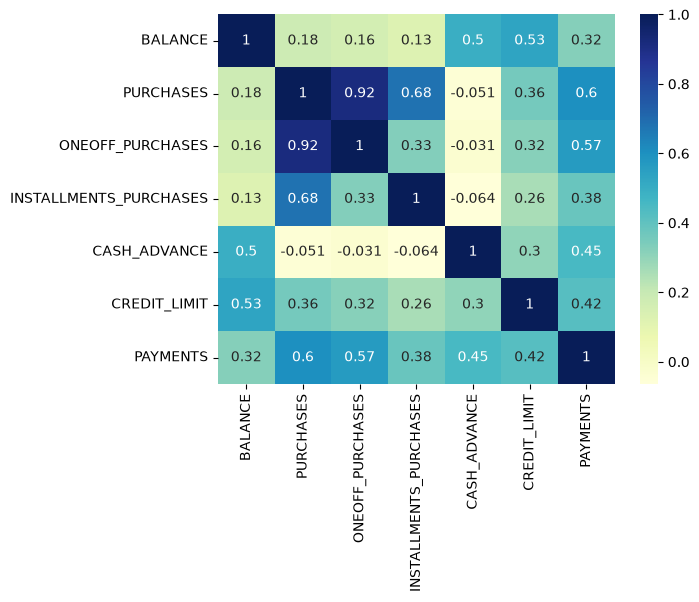

In [ ]:
# Define Correlation using Heatmap : 

correlation_matrix = dataset.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="YlGnBu"
)

correlation_matrix.reset_index()

# there is a good correlation between oneoff_purchases and purchases . 



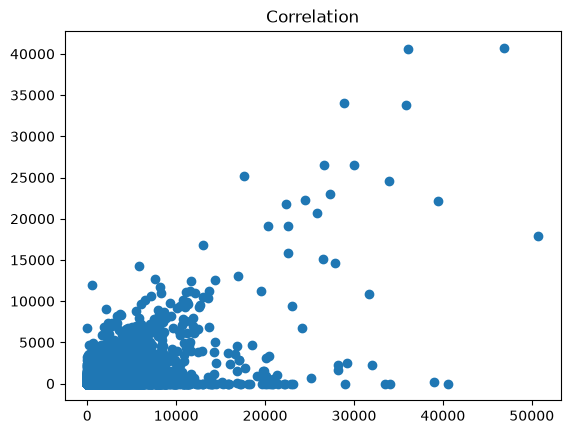

In [55]:
# visualizing the correlation between  PAYMENTS and ONEOFF_PURCHASES
plt.scatter(dataset["PAYMENTS"] , dataset["ONEOFF_PURCHASES"])
plt.title("Correlation")

plt.show()

In [ ]:
# defining outliers : 
columns = dataset.select_dtypes(include="number").columns

result = {}
for column in columns : 
    
    Q1 = dataset[column].quantile(0.25)
    
    Q3 = dataset[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    result[column] = len(dataset[
        (dataset[column] < lower_bound) |
        (dataset[column] > upper_bound)
    ])


result 


128.2819155
39.635
0.0
0.0
0.0
1600.0
383.276166


{'BALANCE': 695,
 'PURCHASES': 808,
 'ONEOFF_PURCHASES': 1013,
 'INSTALLMENTS_PURCHASES': 867,
 'CASH_ADVANCE': 1030,
 'CREDIT_LIMIT': 248,
 'PAYMENTS': 808}

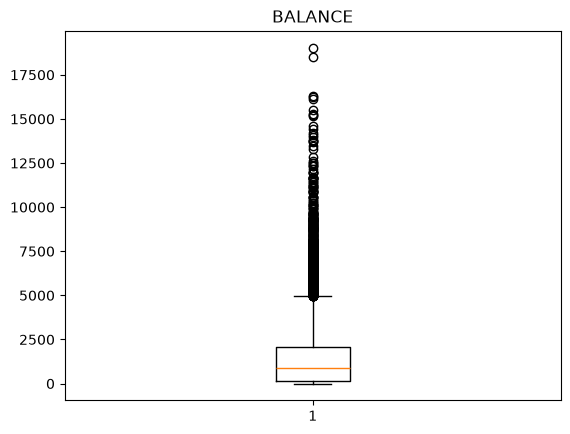

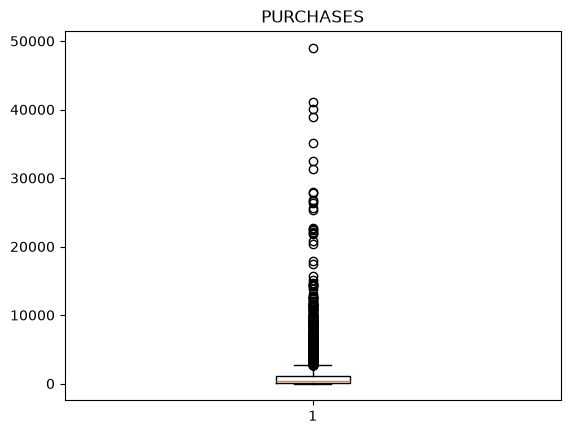

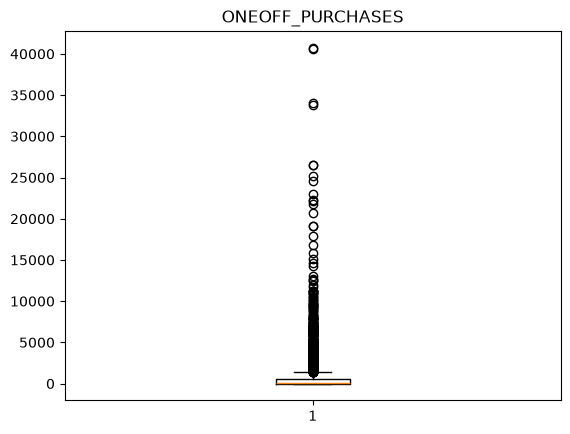

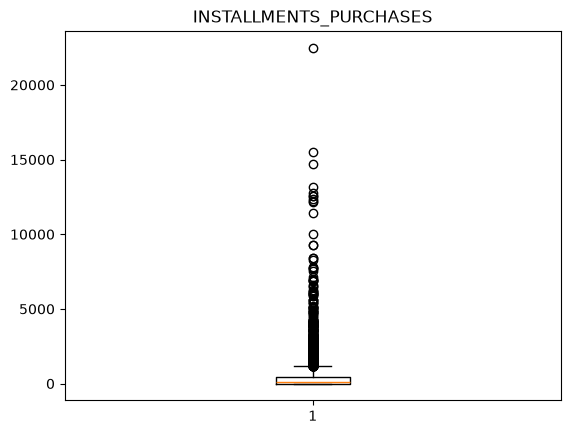

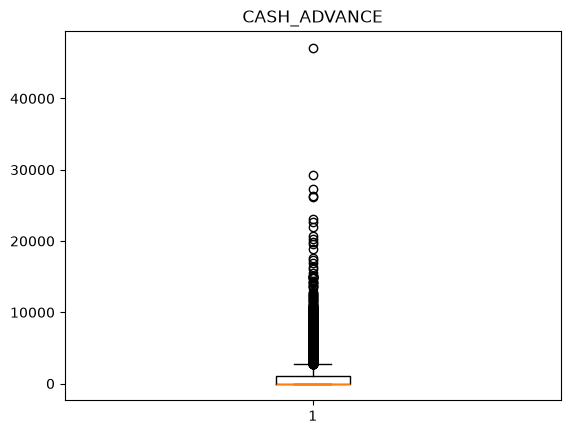

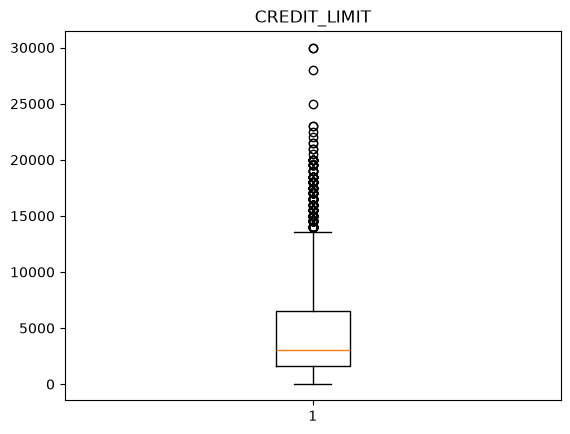

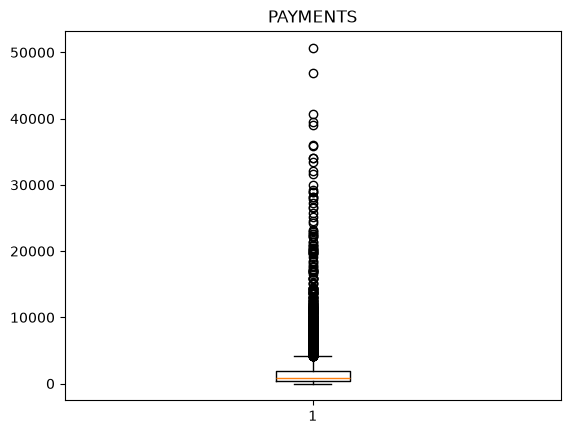

In [159]:
# boxplot for visulazing outliers  : 
for column in columns : 
    
    plt.boxplot(dataset[column])
    plt.title(f"{column}")
    plt.show()

In [ ]:
# summary table : 

column_name = []
values = []
for column in columns : 
    
    nan_values_count = dataset[column].isna().sum()
    column_name.append(column)
    values.append(nan_values_count)
    
    
simple_table = pd.DataFrame(
    
    {
      "columns": column_name,
      "values": values
      
    }
)
    
simple_table.sort_values(by="values", ascending=False)

,columns,values
5,CREDIT_LIMIT,1
1,PURCHASES,0
0,BALANCE,0
2,ONEOFF_PURCHASES,0
3,INSTALLMENTS_PURCHASES,0
4,CASH_ADVANCE,0
6,PAYMENTS,0
